# Comp Lab 2 - Designing a Novel Protein with ESM3

**BIO 462/594 | Thu Nov 5, 2026 | OSC 40 GB GPU | Teams of 2**

Use ESM3 to design protein sequences under specified sequence or structural constraints.
Compare the predicted structures and their per-residue confidence scores. These are computational
predictions, not experimental evidence of folding, stability, catalytic activity, or biological function.

**How this works:** A prompt specifies known amino acids or coordinates. An underscore (`_`)
marks a sequence position to be designed. ESM3 samples amino acids at masked positions and
predicts structures for the resulting sequences.

**Workflow:** Set your assigned team number in Part 1, run the required code cells in order,
and complete the numbered team-response sections. Do not change the prompt during the initial run.
Prompt modifications belong to the optional follow-up experiment after Part 5.
Each team produces three PDB files, one confidence plot, and a written candidate comparison.

---
## Part 0 - Setup (run this, then wait for your instructor)

The model weights are pre-staged on OSC project storage - this cell points the HuggingFace client at
them and loads ESM3 onto the GPU. **The first load takes 1–2 minutes.** Run it now, while your
instructor frames the session.

In [29]:
import os
# Load weights OFFLINE from project storage, with no student token or download.
os.environ['HF_HOME'] = os.environ.get('ESM3_HF_CACHE', '/fs/ess/PNS0503/hf_cache')
os.environ['HF_HUB_CACHE'] = os.path.join(os.environ['HF_HOME'], 'hub')
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['HF_HUB_DISABLE_IMPLICIT_TOKEN'] = '1'

import torch
if not torch.cuda.is_available():
    raise RuntimeError('Lab 2 requires a GPU. Restart Classroom Jupyter with 1 GPU and select the BIO 462/594 Lab 2 - ESM3 kernel.')
device = 'cuda'
print('device:', torch.cuda.get_device_name(0))

from esm.models.esm3 import ESM3
from esm.sdk.api import ESMProtein, GenerationConfig

model = ESM3.from_pretrained('esm3-open').to(device)
print('ESM3-open loaded (1.4B parameters)')

device: NVIDIA A100-PCIE-40GB MIG 7g.40gb
ESM3-open loaded (1.4B parameters)


---
## Part 1 - Your design brief

**Required code:** Set `TEAM` to the number assigned by your instructor, then run the next cell.
Read your biological problem, constraints, and generation settings. Keep the provided settings for the initial run.

In [47]:
import pandas as pd
menu = pd.read_csv('data/design_menu.csv')

TEAM = 5   # <-- YOUR TEAM NUMBER (1-10)

row = menu[menu.team == TEAM].iloc[0]
print(f"TEAM {TEAM}: {row['problem']}")
print()
print('Story:', row['story'])
print()
print('Expected outcome:', row['expected'])
print()
print('INTENSITY:', row['intensity'], '/ 5 -', row['intensity_why'])
print()
print('Generation settings: sequence steps =', row['seq_steps'],
      '| temperature =', row['seq_temp'], '| structure steps =', row['struct_steps'])

TEAM 5: Build a next-generation drug target

Story: About a quarter of all drugs work on membrane proteins - receptors and channels embedded in the cell surface - yet they remain among the hardest proteins to design and study. You plant hydrophobic bands (L/I/V) where the cell membrane would sit and let ESM3 connect them into a bundle. In a real membrane protein the hydrophobic i.e. water-hating residues all point outward into the oily core of the membrane. After you generate, check whether your design does the same - if they are scattered, the protein would never survive in a membrane.

Expected outcome: Alpha-helical bundle; the hydrophobic residues should all face the same direction, ready to sink into a membrane. Worth discussing: how would ESM3 know anything about membranes?

INTENSITY: 4 / 5 - Membrane proteins are rare in the training data, so the model has fewer examples to lean on.

Generation settings: sequence steps = 32 | temperature = 0.8 | structure steps = 16


### Team response 1 - Design objective (2 minutes; no code changes)

Double-click this Markdown cell and replace the blanks with your team's answers.
- Team number: ____
- Biological design objective: ____
- Sequence or structural features that must be retained: ____
- One experimental measurement needed to test the proposed function: ____

When finished, continue to Part 2.

---
## Part 2 - Build your prompt

The prompt is an `ESMProtein` whose `sequence` mixes **fixed** residues and **masked** positions (`_`).
**Required code:** Run the entire next cell unchanged. It selects the appropriate branch for your team automatically.

**Team 3 only:** Type the desired number of amino acids into the input box and press Enter.
Press Enter without typing to use the menu default (350). Longer sequences require more
computation and memory; this input does not guarantee that every length will fit on the GPU.
To change the length later, rerun this cell and Part 3, then rerun the comparisons and Parts 4-5.
Save earlier results first because rerunning generation replaces candidate files.

In [48]:
scaffold_type = row['scaffold_type']

if scaffold_type == 'masked_sequence':
    # Your scaffold is a string: fixed residues + '_' masks
    scaffold = row['scaffold']
    if TEAM == 3:
        default_length = len(scaffold)
        while True:
            answer = input(f'Team 3: number of amino acids (Enter for {default_length}): ').strip()
            if not answer:
                prompt_length = default_length
                break
            try:
                prompt_length = int(answer)
            except ValueError:
                print('Enter a positive whole number, such as 200 or 350.')
                continue
            if prompt_length > 0:
                break
            print('The number of amino acids must be greater than zero.')
        scaffold = '_' * prompt_length
    prompt = ESMProtein(sequence=scaffold)
    n_masked = scaffold.count('_')
    print(f'prompt length {len(scaffold)}, {n_masked} masked positions for ESM3 to design')

elif scaffold_type == 'motif_pdb':
    # Retain the motif sequence and coordinates from PDB 1ITU.
    import numpy as np
    motif = np.load(row['scaffold'])
    motif_seq = str(motif['sequence'])
    motif_coords = motif['atom37']
    L = 150
    full_seq = ['_'] * L
    full_seq[30:30 + len(motif_seq)] = list(motif_seq)   # place the motif inside a masked frame
    full_coords = np.full((L, 37, 3), np.nan, dtype=np.float32)
    full_coords[30:30 + len(motif_seq)] = motif_coords
    prompt = ESMProtein(sequence=''.join(full_seq), coordinates=torch.from_numpy(full_coords))
    print(f'motif "{motif_seq}" fixed at residues 31-{30 + len(motif_seq)} of a {L}-aa frame')

elif scaffold_type == 'rescue':
    # You start from a real p53 fragment (residues 157-246) carrying the Y220C
    # mutation. Part 3 predicts its structure, designs new sequences by inverse
    # folding, and predicts structures for those redesigned sequences.
    prompt = ESMProtein(sequence=row['scaffold'])
    print(f'starting sequence ({len(row.scaffold)} aa, p53 residues 157-246 with the Y220C cancer mutation):')
    print(row['scaffold'])

print()
print('prompt ready:', scaffold_type)

prompt length 104, 76 masked positions for ESM3 to design

prompt ready: masked_sequence


### Before generation - Check your input (no code changes)

Confirm that the printed prompt type matches your design brief.
- `masked_sequence`: fixed amino acids are retained; underscores mark positions to design.
- `motif_pdb`: the motif sequence and its coordinates are provided as constraints.
- `rescue`: the original p53 Y220C sequence is used as a reference for redesign.

**Keep the selected prompt for this run and continue to Part 3.**

---
## Part 3 - Generate sequences and predict structures

**Required code:** Run the next cell without changing the settings. Sequence generation fills
masked positions; structure generation predicts coordinates for the resulting sequence.
`num_steps` controls the number of sampling iterations. Temperature changes the sampling
distribution: higher values generally increase sequence diversity, not biological safety.

**Most teams:** Generate three sequences and predict their structures.
**p53 redesign teams (`rescue`):** Candidate 1 is the original Y220C sequence and its predicted
structure. Candidates 2 and 3 are new sequences designed from that reference structure by
**inverse folding** (structure-conditioned sequence design). Each new sequence then receives
an independent structure prediction. This does not demonstrate restored p53 function.

The export helper writes ESM3 pLDDT scores into PDB B-factors on a 0-100 scale.

In [49]:
from copy import deepcopy
from collections import Counter
from esm.sdk.api import ESMProteinError
from pdb_confidence import save_pdb_with_plddt

N_CANDIDATES = 5

def generate_checked(protein, config):
    result = model.generate(deepcopy(protein), config)
    if isinstance(result, ESMProteinError):
        raise RuntimeError(f'ESM3 generation failed: {result}')
    return result

def report_sequence_quality(sequence, label):
    counts = Counter(sequence)
    residue, count = counts.most_common(1)[0]
    print(f'{label}: {len(counts)} amino-acid types; most frequent is {residue} ({100 * count / len(sequence):.1f}%)')
    if count / len(sequence) >= 0.5:
        print('WARNING: one amino acid occupies at least 50% of this sequence. This is a low-complexity candidate, not evidence of a successful design.')
    if TEAM == 4:
        print(f"Cysteines: {counts['C']}. Sequence alone does not establish disulfide connectivity or activity.")
        if counts['C'] % 2:
            print('WARNING: an odd cysteine count cannot be fully paired into intramolecular disulfide bonds.')

candidates = []
if scaffold_type == 'rescue':
    folded = generate_checked(prompt, GenerationConfig(track='structure', num_steps=int(row['struct_steps'])))
    save_pdb_with_plddt(folded, f'team{TEAM}_candidate1_original.pdb')
    candidates.append({'i': 1, 'sequence': prompt.sequence, 'pdb': f'team{TEAM}_candidate1_original.pdb'})
    print('candidate 1: predicted structure of the original p53 Y220C sequence')
    for i in range(2, N_CANDIDATES + 1):
        design_input = deepcopy(folded)
        design_input.sequence = None
        seq_gen = generate_checked(design_input, GenerationConfig(track='sequence', num_steps=int(row['seq_steps']),
                                                                 temperature=float(row['seq_temp'])))
        report_sequence_quality(seq_gen.sequence, f'Candidate {i}')
        # Use a sequence-only input to obtain a new, independent structure prediction.
        struct_gen = generate_checked(ESMProtein(sequence=seq_gen.sequence), GenerationConfig(
            track='structure', num_steps=int(row['struct_steps'])))
        pdb_file = f'team{TEAM}_candidate{i}_redesigned.pdb'
        save_pdb_with_plddt(struct_gen, pdb_file)
        candidates.append({'i': i, 'sequence': seq_gen.sequence, 'pdb': pdb_file})
        print(f'candidate {i}: predicted structure of a redesigned p53 sequence -> {pdb_file}')
else:
    for i in range(N_CANDIDATES):
        seq_gen = generate_checked(
            prompt,
            GenerationConfig(track='sequence', num_steps=int(row['seq_steps']),
                             temperature=float(row['seq_temp'])),
        )
        report_sequence_quality(seq_gen.sequence, f'Candidate {i + 1}')
        struct_gen = generate_checked(
            seq_gen,
            GenerationConfig(track='structure', num_steps=int(row['struct_steps'])),
        )
        pdb_file = f'team{TEAM}_candidate{i + 1}.pdb'
        save_pdb_with_plddt(struct_gen, pdb_file)
        candidates.append({'i': i + 1, 'sequence': seq_gen.sequence, 'pdb': pdb_file})
        print(f'candidate {i + 1}: {len(seq_gen.sequence)} aa -> {pdb_file}')

unique_sequences = len({c['sequence'] for c in candidates})
print(f'Unique sequences: {unique_sequences} of {len(candidates)} candidates')
if unique_sequences < len(candidates):
    print('WARNING: duplicate sequences were generated. Additional sampling does not guarantee distinct designs.')
print('PDB files saved with per-residue pLDDT on the 0-100 scale.')
for c in candidates:
    print(f"Candidate {c['i']} sequence: {c['sequence']}")

100%|██████████| 32/32 [00:01<00:00, 17.42it/s]


Candidate 1: 2 amino-acid types; most frequent is L (93.3%)


100%|██████████| 16/16 [00:00<00:00, 17.23it/s]


candidate 1: 104 aa -> team5_candidate1.pdb


100%|██████████| 32/32 [00:01<00:00, 17.43it/s]


Candidate 2: 2 amino-acid types; most frequent is L (73.1%)


... (10 outputs left out)

100%|██████████| 32/32 [00:01<00:00, 17.41it/s]


Candidate 5: 2 amino-acid types; most frequent is L (96.2%)


100%|██████████| 16/16 [00:00<00:00, 17.23it/s]

candidate 5: 104 aa -> team5_candidate5.pdb
Unique sequences: 5 of 5 candidates
PDB files saved with per-residue pLDDT on the 0-100 scale.
Candidate 1 sequence: LLLLLLLLLLLLLLLLILLLLLLLLLLLLLLLLLLLLILLLLILLLLLLLLLLLLLLLILLLLLLLLLLLLLLLLLLLLILLLILLLLLLLLLLLLLLLLLILL
Candidate 2 sequence: LLLLLLLLLLLLLLLLIIIIIIILLLLLLLLLLLLLLIIIIIIILLLLLLLLLLLLLLIIIIIIILLLLLLLLLLLLLLIIIIIIILLLLLLLLLLLLLLLLLL
Candidate 3 sequence: MLLLLLLLLLLLLLLLIIIIIIILLLLLLLLLLLLLLIIIIIIIIILLLLLLLLLLLLIIIIIIIIILLLLLLLLLLLLIIIIIIIIIIIIIIIIIIIIIIIII
Candidate 4 sequence: LLLLLLLLLLLLLLLLIIIIIIIIIIILLLLLLLLLLIIIIIIIIIIILLLLLLLLLLIIIIIIIIIIILLLLLLLLLLIIIIIIIIIIIIIIIIIIIIIIIII
Candidate 5 sequence: LLLLLLLLLLLLLLLLILLLLLLLLLLLLLLLLLLLLILLLLLLLLLLLLLLLLLLLLILLLLLLLLLLLLLLLLLLLLILLLLLLLLLLLLLLLLLLLLLLLL


### Sequence comparison - Choose the cell for your team

Run **one** of the two comparison cells below without editing its code.
- Masked-sequence or motif teams: run **Cell A** and skip Cell B.
- p53 redesign teams (`rescue`): skip Cell A and run **Cell B**.

The alignment shows candidates at the same residue positions in blocks of 50.
These sequences have equal lengths and shared numbering, so no gap-based MSA is needed.
Yellow highlights sequence differences; red highlights a changed fixed constraint.
The table lists exact positions, so you do not need to count residues manually.

#### Cell A - Masked-sequence and motif teams only
Run this cell. Read the fixed-residue check and use the table to find differences at designed positions.

In [57]:
if scaffold_type in ('masked_sequence', 'motif_pdb'):
    from sequence_comparison import compare_sequences
    comparison_table = compare_sequences(candidates, prompt.sequence, fixed_constraints=True)
else:
    print('This cell is for masked-sequence and motif teams. Run Cell B for p53 redesign.')

Fixed-residue check: PASS
Variable positions: 55


,Position (1-based),Prompt,Constraint,Fixed residue retained,Candidate 1,Candidate 2,Candidate 3,Candidate 4,Candidate 5
0,1,_,Designed,Not applicable,L,L,M,L,L
1,18,_,Designed,Not applicable,L,I,I,I,L
2,19,_,Designed,Not applicable,L,I,I,I,L
3,20,_,Designed,Not applicable,L,I,I,I,L
4,21,_,Designed,Not applicable,L,I,I,I,L
5,22,_,Designed,Not applicable,L,I,I,I,L
6,23,_,Designed,Not applicable,L,I,I,I,L
7,24,_,Designed,Not applicable,L,L,L,I,L
8,25,_,Designed,Not applicable,L,L,L,I,L
9,26,_,Designed,Not applicable,L,L,L,I,L


#### Cell B - p53 redesign teams only
Run this cell. Candidate 1 is the original sequence. Compare candidates 2 and 3 with it using the highlighted alignment, substitution counts, and examples.

In [ ]:
if scaffold_type == 'rescue':
    from sequence_comparison import compare_sequences
    comparison_table = compare_sequences(candidates, prompt.sequence, fixed_constraints=False)
else:
    print('This cell is for p53 redesign teams. Run Cell A for masked-sequence or motif designs.')

### Team response 2 - Interpret your comparison

Double-click this Markdown cell. Use the output of Cell A or B to fill in **only your team's section**.

**Masked-sequence and motif teams:**
- Example residue positions where the generated sequences differ: ____
- Are all originally fixed amino acids retained? ____
- Do the differences occur in positions that were masked? ____

**p53 redesign teams:**
- Example substitutions in candidate 2 relative to the original sequence: ____
- Example substitutions in candidate 3 relative to the original sequence: ____
- Why do these sequence changes alone not establish restored p53 function? ____

Continue to Part 4.

---
## Part 4 - Look at your designs

Render each candidate in 3D, colored by the model's per-residue confidence (pLDDT, stored in the
PDB B-factor column on a 0-100 scale - the same convention AlphaFold DB uses).
Run both visualization cells. To inspect another candidate, change the index in
`show(candidates[0]['pdb'])` to `1` or `2` and rerun that cell.
pLDDT estimates local structural confidence; it does not measure activity or stability.

In [56]:
import py3Dmol

def show(pdb_file):
    view = py3Dmol.view(width=450, height=380)
    view.addModel(open(pdb_file).read(), 'pdb')
    view.setStyle({'cartoon': {'colorscheme': {'prop': 'b', 'gradient': 'roygb', 'min': 50, 'max': 90}}})
    view.zoomTo()
    return view

show(candidates[4]['pdb'])

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

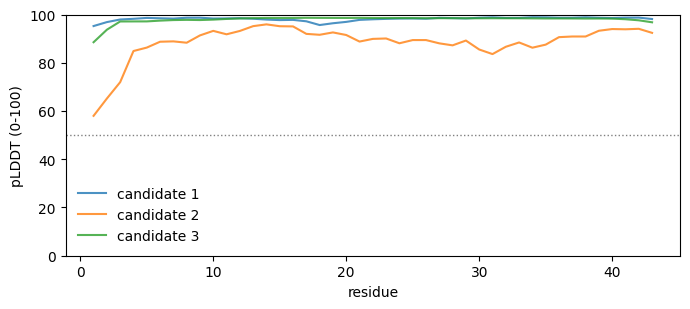

In [37]:
# per-residue pLDDT from the B-factor column (same convention as AlphaFold DB)
import matplotlib.pyplot as plt

def plddt_from_pdb(pdb_file):
    vals = []
    for line in open(pdb_file):
        if line.startswith('ATOM') and line[12:16].strip() == 'CA':
            vals.append(float(line[60:66]))
    if not vals or not any(value > 0 for value in vals):
        raise ValueError('PDB has no usable pLDDT scores. Rerun Part 3 with the updated export helper.')
    return vals

plt.figure(figsize=(7, 3.2))
for c in candidates:
    p = plddt_from_pdb(c['pdb'])
    plt.plot(range(1, len(p) + 1), p, label=f"candidate {c['i']}", alpha=0.8)
plt.axhline(50, color='grey', ls=':', lw=1)
plt.xlabel('residue')
plt.ylabel('pLDDT (0-100)')
plt.ylim(0, 100)
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig(f'team{TEAM}_plddt.png', dpi=140)
plt.show()

---
## Part 5 - Pick your best design

**Required code:** Run the summary table cell below. Compare mean pLDDT, the fraction of
residues below 50, and the locations of low-confidence regions in the plot.
Select a candidate for experimental follow-up using both your design constraints and the structural evidence.

In [8]:
import numpy as np
summary = []
for c in candidates:
    p = plddt_from_pdb(c['pdb'])
    summary.append({'candidate': c['i'],
                    'mean pLDDT': round(float(np.mean(p)), 1),
                    '% residues < 50': round(100 * float(np.mean(np.array(p) < 50)), 0),
                    'length': len(p)})
pd.DataFrame(summary)

,candidate,mean pLDDT,% residues < 50,length
0,1,94.1,0.0,260
1,2,95.3,0.0,260
2,3,91.6,0.0,260


### Team response 3 - Candidate selection (required; no code changes)

Double-click this cell and fill in the answers for your presentation and report.
1. Biological design objective: ____
2. Fixed constraints and positions designed by ESM3: ____
3. Selected candidate number and mean pLDDT: ____
4. Percentage of residues below pLDDT 50: ____
5. A high-confidence region and a low-confidence region (give residue ranges): ____
6. Reasons for choosing this candidate, including limitations of the prediction: ____
7. An experimental test of folding or function: ____

### Optional follow-up experiment - Only after completing the initial analysis
Save your initial notebook and outputs before rerunning code, which replaces candidate files.
With instructor approval, change one allowed constraint or one sampling parameter, record the
change and your prediction, then rerun Parts 2-5. Do not alter required motifs.
This experiment is not required for the initial team analysis.

---
## Part 6 - Wrap-up

**Think, then discuss (3 min):**
1. How does evaluating a designed sequence differ from interpreting a variant in a known protein?
2. What can local structural confidence tell you, and which functional claims remain untested?
3. If the selected protein fails to fold experimentally, which assumptions would you investigate first?

**The Design Report** (30% of the lab portfolio) is assigned today and due **Thursday, November 12**.
Your notebook, your three PDB files, and your Part 5 answers are your source material.

---
## BIO 594 extension

Modify code and document the change (syllabus requirement). Suggested: sweep temperature
(0.5 / 0.7 / 1.0) at fixed prompt and steps, plot mean pLDDT and sequence diversity across
candidates, and report where the diversity–quality tradeoff sits for your problem. Or implement the
structure-conditioned sequence redesign on your own candidate: predict a structure, design a new
sequence by inverse folding, and predict that sequence's structure. Compare sequence identity,
structural similarity, and confidence. Do not interpret higher confidence as restored function.